# BT4012 Fraudulent Bitcoin Transaction Detection - Main Notebook
**Student ID:** e1351028 / AA0296890J \
**Student Name:** Edbert Prathama \
**GitHub Repository:** [https://github.com/edprthm8/bt4012-bitcoin-fraud-detection/](https://github.com/edprthm8/bt4012-bitcoin-fraud-detection/)  
**Competition:** [Kaggle BT4012 Competition 2026](https://www.kaggle.com/competitions/bt-4012-competition-2026/overview)

---

## 1. Overview
This notebook (main notebook which produced my best score) builds a machine learning workflow to detect fraudulent (illicit) Bitcoin transactions in the Elliptic dataset for the [competition](https://www.kaggle.com/competitions/bt-4012-competition-2026/overview). Each row is one Bitcoin transaction, and `txs_edgelist.csv` lists which transaction paid into which. The goal is to give every test transaction a probability of being illicit, scored with ROC-AUC.
- **Class 0 (Licit)**: Everyday payments from regular users, merchants, miners, and exchanges.
- **Class 1 (Illicit)**: Transactions linked to scams, ransomware, darknet markets, and money laundering.

The main challenge is the models are trained on time steps 1–35 but scored on future time steps 36–49, when fraud patterns change (a major darknet market was shut down in this period). A model that only memorizes old fraud will do badly, so every choice in this notebook is checked on future data, not only on random splits.

### Summary
1. **Data Exploration**: Class balance, transactions over time, skewed amounts, and feature correlations.
2. **Feature Engineering & Drift Removal**: Add 25 graph and summary features, then remove 11 features that drift over time (179 features in total).
3. **Temporal Validation**: Train on earlier time steps and test on later ones, to pick models that work on future data. 
4. **Drift-Free Ensemble**: My main model, trained with 5-fold cross-validation and averaged with a second blend.
5. **Final Submission & Analysis**: Test predictions, decision cutoff, and prediction uncertainty.

## 2. Setup
Import the Python libraries for data processing, graph calculations, machine learning models, and plots. 

**Reproducibility:** I fix the random seed (42), so every split, model, and prediction is the same on every run. Two small compatibility functions make HistGradientBoosting and Random Forest give the same results on different scikit-learn versions.

**Speed:** many of the models in this notebook are independent of each other (for example, the ten models of my main ensemble). Instead of training them one after another, I train them at the same time on different CPU cores. Each model still gives exactly the same result as when trained alone; this only saves waiting time. The full notebook takes about 7 minutes on my laptop.

In [1]:
# Install all required packages (or run: pip install -r requirements.txt)
%pip install -q "numpy>=1.20.0" "pandas>=1.3.0" "scipy>=1.7.0" "scikit-learn==1.6.1; python_version < '3.14'" "scikit-learn>=1.8.0; python_version >= '3.14'" "catboost>=1.2.0" "xgboost>=2.0.0" "lightgbm>=4.0.0" "matplotlib>=3.4.0" "seaborn>=0.11.0" "networkx>=2.6.0"


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
# Setup the libraries and environment
import os
# Train each scikit-learn HistGradientBoosting model on one thread. Its results are the same with any number of threads,
# but instead of splitting one model over many cores, I train several independent models at the same time (fit_parallel, Section 6).
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['MKL_NUM_THREADS'] = '1'

import sys
import random
import time
import shutil
import warnings
warnings.filterwarnings('ignore')

# Helper to make sure XGBoost and LightGBM can find the OpenMP library on macOS
# as I got an error previously when running on my Mac
def _ensure_openmp_runtime():
    if sys.platform != 'darwin':
        return
    for sp in sys.path:
        src = os.path.join(sp, 'sklearn', '.dylibs', 'libomp.dylib')
        if os.path.exists(src):
            for pkg in ('xgboost', 'lightgbm'):
                dst_dir = os.path.join(sp, pkg, 'lib')
                dst = os.path.join(dst_dir, 'libomp.dylib')
                if os.path.isdir(dst_dir) and not os.path.exists(dst):
                    try:
                        shutil.copy2(src, dst)
                    except Exception:
                        pass
            break
_ensure_openmp_runtime()

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.sparse import coo_matrix, csr_matrix
from scipy.sparse.csgraph import connected_components
from joblib import Parallel, delayed
import networkx as nx
import sklearn
import catboost
import xgboost as xgb
import lightgbm as lgb

from sklearn.model_selection import StratifiedKFold, StratifiedShuffleSplit
from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, IsolationForest
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.neighbors import NearestNeighbors
from sklearn.svm import SVC
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score,
    precision_score, recall_score, roc_curve,
    precision_recall_curve, confusion_matrix
)
from sklearn.utils import check_random_state, compute_sample_weight
import sklearn.ensemble._forest as _forest
import sklearn.ensemble._hist_gradient_boosting.binning as _hgb_binning
from catboost import CatBoostClassifier

# scikit-learn changed two internal details between versions: how HistGradientBoosting picks its bin edges, and how
# Random Forest draws its bootstrap samples. These two functions pin the behaviour of version 1.6, so the notebook
# gives the same predictions on newer versions too.
def _compat_find_binning_thresholds(col_data, max_bins, sample_weight=None):
    missing_mask = np.isnan(col_data)
    if missing_mask.any():
        col_data = col_data[~missing_mask]
    col_data = np.sort(col_data)
    distinct_values = np.unique(col_data).astype(_hgb_binning.X_DTYPE)
    if len(distinct_values) <= max_bins:
        midpoints = distinct_values[:-1] + distinct_values[1:]
        midpoints *= 0.5
    else:
        percentiles = np.linspace(0, 100, num=max_bins + 1)[1:-1]
        midpoints = np.percentile(col_data, percentiles, method="midpoint").astype(_hgb_binning.X_DTYPE)
    np.clip(midpoints, a_min=None, a_max=_hgb_binning.ALMOST_INF, out=midpoints)
    return midpoints

def _compat_parallel_build_trees(
    tree, bootstrap, X, y, sample_weight, tree_idx, n_trees,
    verbose=0, class_weight=None, n_samples_bootstrap=None,
    missing_values_in_feature_mask=None,
):
    if bootstrap:
        n_samples = X.shape[0]
        curr_sample_weight = np.ones((n_samples,), dtype=np.float64) if sample_weight is None else sample_weight.copy()
        indices = check_random_state(tree.random_state).randint(0, n_samples, n_samples_bootstrap, dtype=np.int32)
        sample_counts = np.bincount(indices, minlength=n_samples)
        curr_sample_weight *= sample_counts
        if class_weight == "balanced_subsample":
            curr_sample_weight *= compute_sample_weight("balanced", y, indices=indices)
        tree._fit(X, y, sample_weight=curr_sample_weight, check_input=False,
                  missing_values_in_feature_mask=missing_values_in_feature_mask)
    else:
        tree._fit(X, y, sample_weight=sample_weight, check_input=False,
                  missing_values_in_feature_mask=missing_values_in_feature_mask)
    return tree

_hgb_binning._find_binning_thresholds = _compat_find_binning_thresholds
_forest._parallel_build_trees = _compat_parallel_build_trees

# Fixed random seed so every split, model, and prediction is the same on every run
RANDOM_SEED = 42
os.environ['PYTHONHASHSEED'] = str(RANDOM_SEED)
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# Number of models trained at the same time (one per CPU core). CatBoost also splits one model over this many cores;
# its documentation states that the thread count does not change its results.
N_THREADS = min(8, os.cpu_count() or 1)

print(f"Python: {sys.version.split()[0]} | scikit-learn: {sklearn.__version__} | CatBoost: {catboost.__version__} | XGBoost: {xgb.__version__} | LightGBM: {lgb.__version__}")
print("Environment setup complete.")

Python: 3.11.9 | scikit-learn: 1.6.1 | CatBoost: 1.2.10 | XGBoost: 3.2.0 | LightGBM: 4.7.0
Environment setup complete.


## 3. Data Loading
Load the transaction features (`train.csv`, `test.csv`) and the payment links between transactions (`txs_edgelist.csv`).

In [3]:
# Load the dataset files
train_df = pd.read_csv('train.csv')
test_df = pd.read_csv('test.csv')
edges_df = pd.read_csv('txs_edgelist.csv')

# Keep the labeled training transactions (0 = Licit, 1 = Illicit). The 110,537 unlabeled rows cannot train a classifier,
# but they still appear in the payment graph, so they are used for the graph features in Section 5.
labeled_mask = train_df['label'].notna()
train_labeled = train_df[labeled_mask].copy().reset_index(drop=True)
train_labeled['label'] = train_labeled['label'].astype(int)

print(f"Train Shape: {train_df.shape}")
print(f"Test Shape:  {test_df.shape}")
print(f"Edges Shape: {edges_df.shape}")
print(f"Labeled Training Samples: {len(train_labeled):,}")

Train Shape: (141772, 168)
Test Shape:  (15329, 168)
Edges Shape: (234355, 2)
Labeled Training Samples: 31,235


## 4. Exploratory Data Analysis (EDA)
Before training models, I explore the dataset to understand:
1. **Class Imbalance**: How rare is fraud in the labeled data? This decides whether I need class weights.
2. **Temporal Trends**: How do transaction counts and fraud rates change across time steps? This decides how I validate the models.
3. **Outliers and Skewness**: Do the features have extreme values? This decides how I scale them for linear and neural models.
4. **Feature Correlations**: Are some features strongly related to each other? This tells me whether the features repeat the same information.

In [4]:
# Class breakdown between licit, illicit, and unlabeled transactions
label_counts = train_labeled['label'].value_counts()
print(f"Licit (0):     {label_counts[0]:,} ({label_counts[0]/len(train_labeled)*100:.1f}% of labeled)")
print(f"Illicit (1):   {label_counts[1]:,} ({label_counts[1]/len(train_labeled)*100:.1f}% of labeled)")
print(f"Unlabeled:     {(~labeled_mask).sum():,} ({(~labeled_mask).sum()/len(train_df)*100:.1f}% of total)")

Licit (0):     27,591 (88.3% of labeled)
Illicit (1):   3,644 (11.7% of labeled)
Unlabeled:     110,537 (78.0% of total)


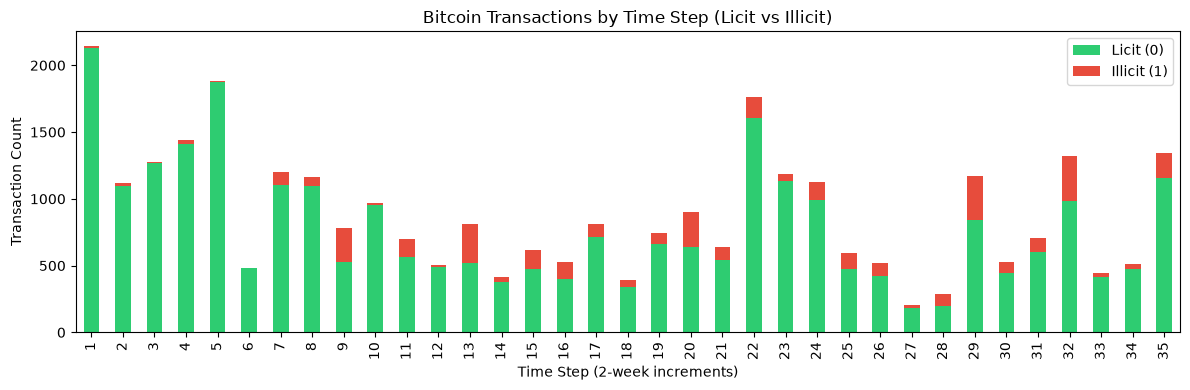

In [5]:
# Transaction counts across each 2-week time step (Licit vs Illicit)
ts_counts = train_labeled.groupby(['time_step', 'label']).size().unstack(fill_value=0)
ts_counts.plot(kind='bar', stacked=True, color=['#2ecc71', '#e74c3c'], figsize=(12, 4))
plt.title('Bitcoin Transactions by Time Step (Licit vs Illicit)')
plt.xlabel('Time Step (2-week increments)')
plt.ylabel('Transaction Count')
plt.legend(['Licit (0)', 'Illicit (1)'])
plt.tight_layout()
plt.show()

In [6]:
# Compare mean/std against median/IQR on feat_53 (a key transaction volume feature).
# If the median/IQR tell a very different story from the mean/std, the feature is skewed by outliers,
# which is why I use RobustScaler (median/IQR) instead of standard z-scores later on.
licit_f53 = train_labeled.loc[train_labeled['label'] == 0, 'feat_53']
illicit_f53 = train_labeled.loc[train_labeled['label'] == 1, 'feat_53']
l_iqr = np.percentile(licit_f53, 75) - np.percentile(licit_f53, 25)
i_iqr = np.percentile(illicit_f53, 75) - np.percentile(illicit_f53, 25)
u_stat, u_pval = stats.mannwhitneyu(licit_f53, illicit_f53)
ks_stat, ks_pval = stats.ks_2samp(licit_f53, illicit_f53)

print("--- Robust vs Parametric Statistics (feat_53 Transaction Volume) ---")
print(f"Licit:   Mean ± Std = {licit_f53.mean():.3f} ± {licit_f53.std():.3f} | Median [IQR] = {licit_f53.median():.3f} [{l_iqr:.3f}]")
print(f"Illicit: Mean ± Std = {illicit_f53.mean():.3f} ± {illicit_f53.std():.3f} | Median [IQR] = {illicit_f53.median():.3f} [{i_iqr:.3f}]")
print(f"Mann-Whitney U p-value: {u_pval:.2e} | KS-Statistic: {ks_stat:.4f} (p = {ks_pval:.2e})")

--- Robust vs Parametric Statistics (feat_53 Transaction Volume) ---
Licit:   Mean ± Std = 1.193 ± 1.537 | Median [IQR] = 0.770 [2.788]
Illicit: Mean ± Std = -0.273 ± 0.525 | Median [IQR] = -0.488 [0.001]
Mann-Whitney U p-value: 0.00e+00 | KS-Statistic: 0.6487 (p = 0.00e+00)


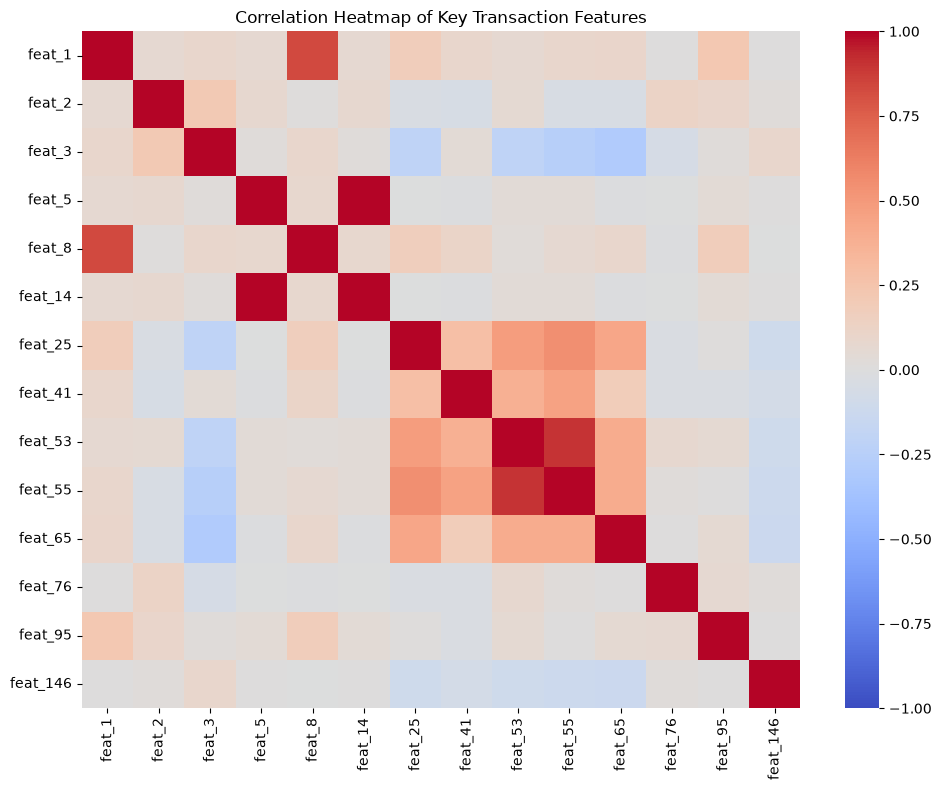

In [7]:
# Correlation heatmap of a sample of key features (strong red/blue blocks = features that repeat the same information)
sample_cols = [f'feat_{i}' for i in [1, 2, 3, 5, 8, 14, 25, 41, 53, 55, 65, 76, 95, 146]]
corr_matrix = train_labeled[sample_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1, annot=False)
plt.title('Correlation Heatmap of Key Transaction Features')
plt.tight_layout()
plt.show()

## 5. Feature Engineering & Drift Removal
The raw data has 165 features: `feat_1`–`feat_94` describe the transaction itself, and `feat_95`–`feat_165` summarise its direct neighbors.

### Graph Features (25 new features)
Fraud often shows up in how money moves, not only in the transaction itself. For example, a "peel chain" quickly splits stolen funds into many small payments, and mixers combine many inputs into one. So I add features that describe each transaction's position in the payment network.

I count links using **all links** in `txs_edgelist.csv`. If I only counted links between transactions that appear in the data files, about 25% of test transactions would look isolated (0% in training), because many of their neighbors are unlabeled and missing from `test.csv`. Counting all links measures training and test transactions in the same way.
1. **Degree & Flow (9)**: incoming, outgoing, and total links, their difference and ratios, and log versions. These show whether a transaction splits money out or collects it in. The log versions shrink very large counts, and I add 1 in the ratios to avoid dividing by zero.
2. **Neighbor Degrees & PageRank (6)**: average and maximum degree of the senders and receivers, and PageRank (how "central" a transaction is) within each time step. I compute PageRank per time step so that links from other periods do not leak in.
3. **Row Summary Statistics (10)**: mean, standard deviation, maximum, and minimum of the local and neighbor features, plus their difference and ratio. They show how unusual a transaction is compared with its neighbors.

### Removing Drifting Features
For each raw feature, I check how well it alone separates training rows from test rows (0 = same distribution, 1 = fully separated). Some features act like a clock: `feat_100`, `feat_101`, `feat_103`, `feat_136`, `feat_137`, and `feat_139` rise steadily with the time step, and a few others (`feat_2`, `feat_106`, `feat_107`, `feat_109`, `feat_115`) also shift strongly between the training and test periods. They tell the model *when* a transaction happened, not how it behaves, and their test values are often outside the training range, so rules learned on them break on the test set.

I remove every raw feature whose separation is above 0.6, which removes 11 features and leaves 179 features. In my experiments, this threshold improved the scores on new fraud patterns without lowering the scores on known patterns.

In [8]:
# Why all links? Compare how many transactions look isolated with each way of counting links
present_ids = set(train_df['txId']) | set(test_df['txId'])
e_present = edges_df[edges_df['txId1'].isin(present_ids) & edges_df['txId2'].isin(present_ids)]
deg_present = pd.concat([e_present['txId1'], e_present['txId2']]).value_counts()
deg_complete = pd.concat([edges_df['txId1'], edges_df['txId2']]).value_counts()

for name, df in [('Train (labeled)', train_labeled), ('Test', test_df)]:
    iso_present = (df['txId'].map(deg_present).fillna(0) == 0).mean() * 100
    iso_complete = (df['txId'].map(deg_complete).fillna(0) == 0).mean() * 100
    kept = df['txId'].map(deg_present).fillna(0).sum() / df['txId'].map(deg_complete).fillna(0).sum() * 100
    print(f"{name:16s}: looks isolated with observed links = {iso_present:5.1f}% | with all links = {iso_complete:4.1f}% | share of links observed = {kept:5.1f}%")

Train (labeled) : looks isolated with observed links =   0.0% | with all links =  0.0% | share of links observed = 100.0%
Test            : looks isolated with observed links =  25.4% | with all links =  0.0% | share of links observed =  51.2%


In [9]:
t_feat = time.time()
local_cols = [f'feat_{i}' for i in range(1, 95)]
agg_cols = [f'feat_{i}' for i in range(95, 166)]

# Step 1: give every node in the graph a time step. Payment links never cross time steps, so every node in a connected
# group of transactions shares the time step of the known transactions in that group. (This matters for the unlabeled
# test-period transactions that are in the edge list but not in test.csv.)
known_ts = pd.concat([train_df[['txId', 'time_step']], test_df[['txId', 'time_step']]])
tx2ts = dict(zip(known_ts['txId'], known_ts['time_step']))
n_edges = len(edges_df)
codes, nodes = pd.factorize(np.r_[edges_df['txId1'].values, edges_df['txId2'].values])
adj = coo_matrix((np.ones(n_edges), (codes[:n_edges], codes[n_edges:])), shape=(len(nodes), len(nodes)))
_, comp = connected_components(adj, directed=False)
comp_ts = pd.Series(nodes).map(tx2ts).groupby(comp).first()          # time step of each connected group
node_ts = dict(zip(nodes, comp_ts.reindex(comp).values))
node_ts.update(tx2ts)

def graph_stats(edges):
    """Degree, neighbor-degree and PageRank lookups for one edge list.
    PageRank is computed inside each time step. alpha=0.85 is the standard value from the original PageRank paper,
    and 50 iterations are enough for these small per-step graphs to converge."""
    e = edges[['txId1', 'txId2']].copy()
    in_deg, out_deg = e['txId2'].value_counts(), e['txId1'].value_counts()
    e['deg1'] = e['txId1'].map(out_deg)                                   # how many outputs the sender has
    e['deg2'] = e['txId2'].map(in_deg)                                    # how many inputs the receiver has
    pred = e.groupby('txId2')['deg1'].agg(['mean', 'max'])                # senders of each transaction
    succ = e.groupby('txId1')['deg2'].agg(['mean', 'max'])                # receivers of each transaction
    pagerank = {}
    for _, g in e.groupby(e['txId1'].map(node_ts)):
        G = nx.DiGraph()
        G.add_edges_from(zip(g['txId1'], g['txId2']))
        pagerank.update(nx.pagerank(G, alpha=0.85, max_iter=50))
    return {'in': in_deg, 'out': out_deg, 'pred_mean': pred['mean'], 'pred_max': pred['max'],
            'succ_mean': succ['mean'], 'succ_max': succ['max'], 'pagerank': pagerank}

def row_stats(df, local=local_cols, agg=agg_cols):
    """10 row summary statistics of the local and neighbor features. They are computed once and shared by both feature sets."""
    s = pd.DataFrame(index=df.index)
    for name, cols in [('local', local), ('agg', agg)]:
        block = df[cols]
        s[f'{name}_mean'], s[f'{name}_std'] = block.mean(axis=1), block.std(axis=1)
        s[f'{name}_max'], s[f'{name}_min'] = block.max(axis=1), block.min(axis=1)
    s = s[['local_mean', 'local_std', 'local_max', 'local_min', 'agg_mean', 'agg_std', 'agg_max', 'agg_min']]
    s['agg_local_diff'] = s['agg_mean'] - s['local_mean']                 # is the transaction unusual compared with its neighbors?
    s['agg_local_ratio'] = (s['agg_mean'] + 1.0) / (s['local_mean'].abs() + 1.0)
    return s

def build_features(df, gs, stats):
    """165 raw features + 15 graph features (from the lookups in gs) + 10 row statistics = 190 features."""
    f = df.copy()
    tx = f['txId']
    lookup = lambda key: tx.map(gs[key]).fillna(0).astype(float)         # transactions without links get 0
    f['in_degree'], f['out_degree'] = lookup('in'), lookup('out')
    f['total_degree'] = f['in_degree'] + f['out_degree']
    f['degree_ratio'] = (f['out_degree'] + 1.0) / (f['in_degree'] + 1.0)       # +1 avoids dividing by zero
    f['in_out_diff'] = f['out_degree'] - f['in_degree']                         # positive = splits money out (peel chains)
    f['net_flow_ratio'] = (f['out_degree'] - f['in_degree']) / (f['total_degree'] + 1.0)
    # log(1 + x) shrinks very large link counts so a few huge hubs do not dominate
    f['log_in_deg'] = np.log1p(f['in_degree'])
    f['log_out_deg'] = np.log1p(f['out_degree'])
    f['log_total_deg'] = np.log1p(f['total_degree'])
    f['pred_deg_mean'], f['succ_deg_mean'] = lookup('pred_mean'), lookup('succ_mean')
    f['log_pred_deg_max'] = np.log1p(lookup('pred_max'))
    f['log_succ_deg_max'] = np.log1p(lookup('succ_max'))
    f['pagerank'] = lookup('pagerank')
    f['log_pagerank'] = np.log1p(f['pagerank'] * 1e4)                            # PageRank values are tiny, so scale up before the log
    return pd.concat([f, stats], axis=1)

# Step 2: graph features from all links
stats_train, stats_test = row_stats(train_labeled), row_stats(test_df)
gs_all = graph_stats(edges_df)
train_feat_df = build_features(train_labeled, gs_all, stats_train)
test_feat_df = build_features(test_df, gs_all, stats_test)
feature_cols = [c for c in train_feat_df.columns if c not in ['txId', 'time_step', 'label', 'index']]
y_full = train_feat_df['label'].values
steps_full = train_feat_df['time_step'].values

print(f"Features built with all links in {time.time()-t_feat:.1f}s: {len(feature_cols)} total (165 raw + 15 graph + 10 row statistics)")
print(f"Mean total_degree -> train: {train_feat_df['total_degree'].mean():.2f} | test: {test_feat_df['total_degree'].mean():.2f}")
print(f"Test transactions with zero links: {(test_feat_df['total_degree'] == 0).sum()} / {len(test_feat_df):,}")

Features built with all links in 1.0s: 190 total (165 raw + 15 graph + 10 row statistics)
Mean total_degree -> train: 2.87 | test: 3.24
Test transactions with zero links: 0 / 15,329


 Feature  Train-vs-test separation  Rank corr. with time step  Fraud signal
feat_101                     0.997                      0.998         0.313
feat_103                     0.997                      0.995         0.318
feat_100                     0.996                      0.993         0.321
feat_136                     0.992                      0.993         0.320
feat_139                     0.953                      0.966         0.274
feat_137                     0.882                      0.906         0.236
  feat_2                     0.725                      0.661         0.072
feat_109                     0.668                      0.611         0.015
feat_106                     0.640                      0.607         0.294
feat_115                     0.616                      0.594         0.180
feat_107                     0.606                      0.545         0.090
feat_151                     0.575                      0.568         0.143

Removed 11 

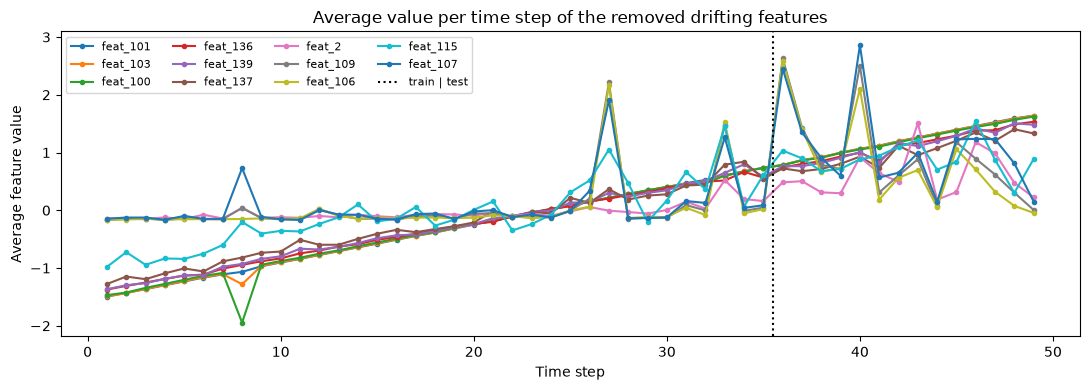

In [10]:
# Find drifting features. No model is trained here: for each raw feature I measure how well the feature ALONE separates
# training rows from test rows, using the ROC-AUC of "is this row from the test set?" rescaled to 0..1
# (0 = train and test look the same, 1 = fully separated). I also record how strongly the feature follows the time step
# and how much fraud signal it carries on its own.
raw_cols = [f'feat_{i}' for i in range(1, 166)]
is_test = np.r_[np.zeros(len(train_labeled)), np.ones(len(test_df))]
both = pd.concat([train_labeled[raw_cols], test_df[raw_cols]], ignore_index=True)
steps_both = np.r_[train_labeled['time_step'].values, test_df['time_step'].values]
drift_rows = []
for c in raw_cols:
    separation = abs(roc_auc_score(is_test, both[c].values) - 0.5) * 2
    step_corr = stats.spearmanr(steps_both, both[c].values).correlation
    fraud_signal = abs(roc_auc_score(y_full, train_labeled[c].values) - 0.5) * 2
    drift_rows.append((c, separation, step_corr, fraud_signal))
drift_df = pd.DataFrame(drift_rows, columns=['Feature', 'Train-vs-test separation', 'Rank corr. with time step', 'Fraud signal'])
drift_df = drift_df.sort_values('Train-vs-test separation', ascending=False).reset_index(drop=True)

# 0.6 removes the clock features and the other strongly shifting ones (all score 0.606 or more); the next feature
# (feat_151) scores 0.575. In my experiments, 0.6 beat 0.7 on new fraud patterns, and 0.5 also removed features that still carry fraud signal.
DRIFT_THRESHOLD = 0.6
drift_cols = drift_df.loc[drift_df['Train-vs-test separation'] > DRIFT_THRESHOLD, 'Feature'].tolist()
final_cols = [c for c in feature_cols if c not in drift_cols]
print(drift_df.head(12).round(3).to_string(index=False))
print(f"\nRemoved {len(drift_cols)} drifting features (separation > {DRIFT_THRESHOLD}): {drift_cols}")
print(f"Drift-free feature set: {len(final_cols)} features")

X_final = train_feat_df[final_cols].values.astype(np.float32)       # 179 drift-free features (float32 halves memory use)
X_test_final = test_feat_df[final_cols].values.astype(np.float32)

# Plot: the removed features simply follow the time step
step_means = pd.concat([train_labeled[['time_step'] + drift_cols], test_df[['time_step'] + drift_cols]]).groupby('time_step').mean()
plt.figure(figsize=(11, 4))
for c in drift_cols:
    plt.plot(step_means.index, step_means[c], marker='.', label=c)
plt.axvline(35.5, color='black', linestyle=':', label='train | test')
plt.title('Average value per time step of the removed drifting features')
plt.xlabel('Time step')
plt.ylabel('Average feature value')
plt.legend(fontsize=8, ncol=4)
plt.tight_layout()
plt.show()

## 6. Temporal Validation
Random cross-validation mixes all time steps, so almost every tree model scores about 0.998 and it is hard to tell them apart. To copy the real test, I train on time steps 1 to `k` and test on steps `k+1` to 35:
- **HARD splits (`k` = 18, 20, 22)**: a new fraud pattern appears around steps 23–24, similar to the change in the test period.
- **EASY splits (`k` = 25, 28, 30)**: the fraud patterns were already seen in training.

I look at both groups: the HARD splits copy a change in fraud patterns, and the EASY splits copy the near future.

### Main Model: the Drift-Free Ensemble (179 features)
It is an equal average of two parts, because each part is good at a different thing:
1. **Tree blend**: 0.50 × CatBoost (600 rounds, trained on SMOTE-balanced data) + 0.45 × HistGradientBoosting (up to 500 rounds, early stopping) + 0.05 × Random Forest (150 trees). It is strongest on known fraud patterns. CatBoost gets the biggest weight because it is the strongest of the three on known patterns, and Random Forest gets a small weight that only smooths out extreme scores.
2. **HistGB ensemble**: three groups of short-trained HistGradientBoosting models, averaged equally. It is strongest on new fraud patterns.
   - **Core**: 150 rounds, at least 15 transactions per leaf. 150 rounds is where the score on new patterns peaks (see the plot below).
   - **Big-leaf**: 150 rounds, at least 60 transactions per leaf. Bigger leaves give simpler rules that do not depend on just a few transactions.
   - **Feature-subsampled**: 250 rounds, each split only sees a random half of the features (5 seeds). This stops the models from all relying on the same few features.

**Shared settings:** a small learning rate (0.04), so each tree only changes the score a little; a depth limit (6–8), so trees cannot memorise single transactions; and balanced class weights, because licit transactions outnumber illicit ones 7.57 to 1.

**SMOTE** (Synthetic Minority Oversampling) creates new illicit examples by mixing each illicit transaction with one of its 5 nearest illicit neighbors, until both classes are the same size. I use it only for CatBoost, because it helped CatBoost on new fraud patterns but not the other models in my experiments.

The ten models of the ensemble are independent, so `fit_parallel` trains them at the same time on different CPU cores.

### Why Averaging the Two Parts
The table below shows the trade-off. The HistGB ensemble alone has the best score on the HARD splits, and the tree blend is slightly better on the EASY splits and in the random-fold cross-validation of Section 7. Averaging them gives up part of the HARD gain but gives the best EASY score, and two different kinds of models make different mistakes, which makes the final ranking more stable. My public leaderboard scores pointed the same way: a submission with only short-trained HistGB models scored 0.95169, the Drift-Free Ensemble 0.95194, and adding the second blend of Section 7 gave 0.95228; removing the 11 drifting features, SMOTE for CatBoost, and the drift-free second blend then raised it to 0.95247. Each step is small (the public leaderboard uses only about 30% of the test data), but they all moved in the same direction.

In [ ]:
# ----- model definitions, with the reason for each setting -------
def hgb_member(rounds, min_leaf, max_features=1.0, seed=RANDOM_SEED):
    """One short-trained HistGradientBoosting model with a fixed number of rounds."""
    return HistGradientBoostingClassifier(
        max_iter=rounds,             # number of trees: 150-250 is where the score on NEW fraud patterns peaks (plot below)
        learning_rate=0.04,          # small steps: each tree changes the score only a little, which generalises better
        max_depth=8,                 # trees cannot grow deep enough to memorise single transactions
        min_samples_leaf=min_leaf,   # every rule must cover at least this many transactions
        max_features=max_features,   # share of the features each split may look at (0.5 = a random half)
        class_weight='balanced',     # illicit rows count 7.57x more, because licit rows outnumber them 7.57 to 1
        early_stopping=False,        # train exactly `rounds` trees, so nothing depends on a random validation split
        random_state=seed)

def make_hgb500(seed):
    """HistGradientBoosting with up to 500 rounds. scikit-learn holds out 10% of the rows and stops when they stop improving."""
    return HistGradientBoostingClassifier(max_iter=500, learning_rate=0.04, max_depth=8, min_samples_leaf=15,
                                          class_weight='balanced', random_state=seed)

def make_catboost(seed, rounds=600, balanced=False):
    """CatBoost with simple, well-regularized trees."""
    return CatBoostClassifier(
        iterations=rounds, learning_rate=0.04,   # same small learning rate as the other boosting models
        depth=6,                                 # CatBoost trees are symmetric; depth 6 (64 leaves) is enough here
        l2_leaf_reg=4,                           # penalty on leaf values (default 3); a bit more smoothing of the scores
        auto_class_weights='Balanced' if balanced else None,   # SMOTE data is already balanced, so no weights there
        thread_count=N_THREADS, random_seed=seed, verbose=0)

def make_rf(seed):
    """Random Forest: 150 trees of depth at most 14 (deeper trees memorize the training data)."""
    return RandomForestClassifier(n_estimators=150, max_depth=14, class_weight='balanced', n_jobs=4, random_state=seed)

def make_xgb(pos_w, seed):
    """Benchmark XGBoost: 80% row and feature sampling, L2 penalty 2, and scale_pos_weight (XGBoost's class weight).
    400 rounds on purpose, to show what happens when boosting runs much longer than 150 rounds."""
    return xgb.XGBClassifier(n_estimators=400, learning_rate=0.04, max_depth=6, min_child_weight=5, subsample=0.8,
                             colsample_bytree=0.8, reg_lambda=2.0, scale_pos_weight=pos_w, tree_method='hist',
                             n_jobs=4, random_state=seed, eval_metric='logloss')

def make_lgb(seed):
    """Benchmark LightGBM with the same sampling and penalty as XGBoost, 63 leaves, depth 8, 400 rounds."""
    return lgb.LGBMClassifier(n_estimators=400, learning_rate=0.04, num_leaves=63, max_depth=8, min_child_samples=15,
                              subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=2.0,
                              class_weight='balanced', n_jobs=4, random_state=seed, verbose=-1)

def smote(X, y, k=5, seed=RANDOM_SEED):
    """SMOTE: add synthetic illicit rows until both classes have the same size.
    Each new row lies on the line between an illicit row and one of its k=5 nearest illicit neighbors (the usual SMOTE
    setting). Neighbors are found on robust-scaled features, so that features with big values do not dominate the
    distance; the new rows themselves are created in the original feature space."""
    rng = np.random.RandomState(seed)
    X_min = X[y == 1]
    Z_min = np.clip(RobustScaler().fit(X).transform(X_min), -10, 10)
    n_new = int((y == 0).sum() - (y == 1).sum())
    _, idx = NearestNeighbors(n_neighbors=k + 1).fit(Z_min).kneighbors(Z_min)
    base = rng.randint(0, len(X_min), n_new)
    neighbor = idx[base, rng.randint(1, k + 1, n_new)]
    gap = rng.rand(n_new, 1).astype(np.float32)
    X_new = X_min[base] + gap * (X_min[neighbor] - X_min[base])
    return np.vstack([X, X_new]), np.r_[y, np.ones(n_new, dtype=int)]

# ---------- training several models at the same time ----------
def fit_parallel(jobs):
    """Fit several models at the same time, one per thread. jobs = list of (model, X, y) or (model, X, y, extra_fit_arguments).
    Every fit has its own fixed seed and shares nothing with the others, so each result is exactly the same as when the
    model is trained alone. This only saves waiting time."""
    fit_one = lambda m, X, y, kw=None: m.fit(X, y, **(kw or {}))
    return Parallel(n_jobs=N_THREADS, prefer='threads')(delayed(fit_one)(*job) for job in jobs)

def blend3(p_cb, p_hgb, p_rf):
    """Tree blend weights: CatBoost 0.50 (strongest on known patterns), HistGB 0.45, Random Forest 0.05 (smooths extreme scores)."""
    return 0.50 * p_cb + 0.45 * p_hgb + 0.05 * p_rf

def drift_free_models(X_tr, y_tr, seed=RANDOM_SEED, extra=None):
    """Fit the 10 models of the Drift-Free Ensemble at the same time (plus any extra models, trained on the same rows).
    Tree blend: CatBoost on SMOTE-balanced data, HistGB (500 rounds), Random Forest.
    HistGB ensemble: core, big-leaf, and 5 feature-subsampled models (seeds seed+0 ... seed+4)."""
    X_sm, y_sm = smote(X_tr, y_tr, seed=seed)
    models = {'CatBoost (SMOTE)': make_catboost(seed), 'HistGB (500 rounds)': make_hgb500(seed), 'Random Forest': make_rf(seed),
              'core': hgb_member(150, 15, seed=seed), 'big_leaf': hgb_member(150, 60, seed=seed)}
    models.update({f'feat_sub_{s}': hgb_member(250, 15, max_features=0.5, seed=seed + s) for s in range(5)})
    models.update(extra or {})
    jobs = [(m, X_sm, y_sm) if name == 'CatBoost (SMOTE)' else (m, X_tr, y_tr) for name, m in models.items()]
    return dict(zip(models, fit_parallel(jobs)))

def drift_free_predict(models, X):
    """Illicit probability of every model, the two parts, and the Drift-Free Ensemble."""
    p = {name: m.predict_proba(X)[:, 1] for name, m in models.items()}
    p['Tree blend'] = blend3(p['CatBoost (SMOTE)'], p['HistGB (500 rounds)'], p['Random Forest'])
    p['feat_sub'] = np.mean([p[f'feat_sub_{s}'] for s in range(5)], axis=0)
    p['HistGB ensemble'] = np.mean([p['core'], p['big_leaf'], p['feat_sub']], axis=0)
    p['Drift-Free Ensemble'] = 0.5 * p['Tree blend'] + 0.5 * p['HistGB ensemble']
    return p

# ---------- temporal validation -----
# Train on steps 1..k, validate on k+1..35. HARD splits (18, 20, 22) contain the new fraud pattern around steps 23-24.
SPLITS = [18, 20, 22, 25, 28, 30]
HARD_SPLITS = [18, 20, 22]
CURVE_ROUNDS = [25, 50, 100, 150, 200, 300, 400]
TABLE = ['CatBoost (SMOTE)', 'HistGB (500 rounds)', 'Random Forest', 'XGBoost (400 rounds)', 'LightGBM (400 rounds)',
         'Tree blend', 'HistGB ensemble', 'Drift-Free Ensemble']
val_preds, val_rows, curves = {}, [], {}          # val_preds keeps every validation prediction
t_val = time.time()

for k in SPLITS:
    tr, va = steps_full <= k, steps_full > k
    y_tr, y_va = y_full[tr], y_full[va]
    pos_w = (y_tr == 0).sum() / (y_tr == 1).sum()
    extra = {'XGBoost (400 rounds)': make_xgb(pos_w, RANDOM_SEED), 'LightGBM (400 rounds)': make_lgb(RANDOM_SEED)}
    if k == 20:                                   # one long HistGB run, to plot the score after different numbers of rounds
        extra['hgb_long'] = hgb_member(max(CURVE_ROUNDS), 15)
    models = drift_free_models(X_final[tr], y_tr, extra=extra)
    p = drift_free_predict(models, X_final[va])
    val_preds[k] = p
    val_rows.append({'Split': k, **{name: roc_auc_score(y_va, p[name]) for name in TABLE}})

    if k == 20:
        Xv = X_final[va]
        curves['HistGradientBoosting'] = [roc_auc_score(y_va, pp[:, 1]) for i, pp in enumerate(models['hgb_long'].staged_predict_proba(Xv), start=1) if i in CURVE_ROUNDS]
        curves['XGBoost'] = [roc_auc_score(y_va, models['XGBoost (400 rounds)'].predict_proba(Xv, iteration_range=(0, n))[:, 1]) for n in CURVE_ROUNDS]
        curves['LightGBM'] = [roc_auc_score(y_va, models['LightGBM (400 rounds)'].predict_proba(Xv, num_iteration=n)[:, 1]) for n in CURVE_ROUNDS]
        curves['CatBoost'] = [roc_auc_score(y_va, models['CatBoost (SMOTE)'].predict_proba(Xv, ntree_end=n)[:, 1]) for n in CURVE_ROUNDS]
    print(f"  Split Train 1-{k} -> Val {k+1}-35 done ({y_va.sum()} illicit in validation)")

val_df = pd.DataFrame(val_rows).set_index('Split').T
val_df['HARD (18,20,22)'] = val_df[HARD_SPLITS].mean(axis=1)
val_df['EASY (25,28,30)'] = val_df[[s for s in SPLITS if s not in HARD_SPLITS]].mean(axis=1)
val_df['ALL'] = val_df[SPLITS].mean(axis=1)
pd.set_option('display.width', 220)
print(f"\n=== Temporal Validation ROC-AUC, 179 features (completed in {time.time()-t_val:.0f}s) ===")
print(val_df.round(4).sort_values('EASY (25,28,30)', ascending=False).to_string())

  Split Train 1-18 -> Val 19-35 done (2213 illicit in validation)
  Split Train 1-20 -> Val 21-35 done (1873 illicit in validation)
  Split Train 1-22 -> Val 23-35 done (1615 illicit in validation)
  Split Train 1-25 -> Val 26-35 done (1307 illicit in validation)
  Split Train 1-28 -> Val 29-35 done (1102 illicit in validation)
  Split Train 1-30 -> Val 31-35 done (690 illicit in validation)

=== Temporal Validation ROC-AUC, 179 features (completed in 81s) ===
Split                      18      20      22      25      28      30  HARD (18,20,22)  EASY (25,28,30)     ALL
LightGBM (400 rounds)  0.8618  0.8598  0.8219  0.9976  0.9977  0.9984           0.8478           0.9979  0.9229
XGBoost (400 rounds)   0.8698  0.8891  0.8732  0.9974  0.9975  0.9984           0.8774           0.9978  0.9376
Drift-Free Ensemble    0.9269  0.9128  0.8983  0.9972  0.9977  0.9984           0.9127           0.9978  0.9552
Tree blend             0.9226  0.9030  0.8614  0.9972  0.9976  0.9984           0.8957 

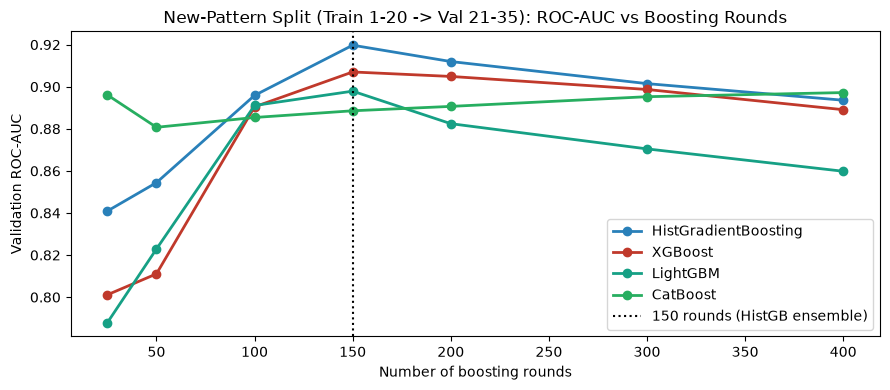

In [12]:
# How the number of boosting rounds changes the score when a new fraud pattern appears (split Train 1-20, 179 features)
plt.figure(figsize=(9, 4))
colors = {'HistGradientBoosting': '#2980b9', 'XGBoost': '#c0392b', 'LightGBM': '#16a085', 'CatBoost': '#27ae60'}
for name, vals in curves.items():
    plt.plot(CURVE_ROUNDS, vals, marker='o', label=name, color=colors[name], lw=2)
plt.axvline(150, color='black', linestyle=':', label='150 rounds (HistGB ensemble)')
plt.title('New-Pattern Split (Train 1-20 -> Val 21-35): ROC-AUC vs Boosting Rounds')
plt.xlabel('Number of boosting rounds')
plt.ylabel('Validation ROC-AUC')
plt.legend()
plt.tight_layout()
plt.show()

## 7. Model Training
I train the benchmark models and the Drift-Free Ensemble on all 31,235 labeled transactions with 5-fold stratified cross-validation. "Stratified" means every fold keeps the same 11.7% fraud rate. Each model's test prediction is the average of its 5 fold models, which is more stable than one model trained once.
- **Benchmarks**: Logistic Regression (L2 Ridge and L1 Lasso), a single Decision Tree, a Neural Network (MLP), XGBoost, and LightGBM. They show how much the more complex models actually add.
- **Drift-Free Ensemble (179 features)**: the tree blend (CatBoost on SMOTE-balanced data, HistGradientBoosting, Random Forest) and the HistGB ensemble.
- **Scaling**: only the linear models and the MLP use scaled features (`RobustScaler`, median and IQR, clipped to ±10), because they are sensitive to extreme values. Tree models split on thresholds, so they do not need scaling.

These random-fold scores are much higher than the temporal validation scores, because random folds mix all time steps. I use them as a sanity check and to choose the decision cutoff.

In [13]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
folds = list(skf.split(X_final, y_full))

DF_PARTS = ['CatBoost (SMOTE)', 'HistGB (500 rounds)', 'Random Forest', 'Tree blend', 'HistGB ensemble']
oof = {}                                            # out-of-fold predictions of every model, for the benchmark table
test_blend_part = np.zeros(len(X_test_final))       # test predictions of the tree blend, averaged over the 5 folds
test_ens_part = np.zeros(len(X_test_final))         # test predictions of the HistGB ensemble, averaged over the 5 folds

print("Training the benchmark models and the Drift-Free Ensemble on 5 stratified folds...")
t_cv = time.time()
for fold, (trn_idx, val_idx) in enumerate(folds):
    X_tr, y_tr = X_final[trn_idx], y_full[trn_idx]
    X_va, y_va = X_final[val_idx], y_full[val_idx]
    seed = RANDOM_SEED + fold                       # a different (but fixed) seed in each fold
    pos_w = (y_tr == 0).sum() / (y_tr == 1).sum()

    # Scaling is fitted on the training fold only (no information from the validation fold leaks in).
    # RobustScaler uses the median and IQR, so outliers do not distort it; clipping to +-10 limits extreme values.
    scaler = RobustScaler().fit(X_tr)
    X_tr_sc = np.clip(scaler.transform(X_tr), -10, 10)
    X_va_sc = np.clip(scaler.transform(X_va), -10, 10)

    # 1. Benchmark models, all six fitted at the same time. Linear and neural models use the scaled features.
    #    L2 Ridge (C=1.0): standard penalty. L1 Lasso (C=0.1): stronger penalty that drops weak features (liblinear supports L1).
    #    MLP: two small hidden layers (64, 32) with early stopping, so it stops before it overfits.
    #    Decision Tree: depth 6 keeps it small and readable as a simple baseline.
    scaled_models = {
        'Logistic Regression (L2 Ridge)': LogisticRegression(penalty='l2', C=1.0, class_weight='balanced', max_iter=200, random_state=seed),
        'Logistic Regression (L1 Lasso)': LogisticRegression(penalty='l1', solver='liblinear', C=0.1, class_weight='balanced', max_iter=200, random_state=seed),
        'Neural Network (MLP)': MLPClassifier(hidden_layer_sizes=(64, 32), activation='relu', alpha=1e-4, max_iter=150, early_stopping=True, random_state=seed),
    }
    raw_models = {
        'Single Decision Tree': DecisionTreeClassifier(max_depth=6, class_weight='balanced', random_state=seed),
        'XGBoost (400 rounds)': make_xgb(pos_w, seed),
        'LightGBM (400 rounds)': make_lgb(seed),
    }
    bench = list(scaled_models.items()) + list(raw_models.items())
    fitted = fit_parallel([(m, X_tr_sc, y_tr) for _, m in scaled_models.items()] + [(m, X_tr, y_tr) for _, m in raw_models.items()])
    for (name, _), m in zip(bench, fitted):
        oof.setdefault(name, np.zeros(len(y_full)))[val_idx] = m.predict_proba(X_va_sc if name in scaled_models else X_va)[:, 1]

    # 2. Drift-Free Ensemble: the ten models fitted at the same time, then predicted on the validation fold and the test set
    models = drift_free_models(X_tr, y_tr, seed=seed)
    p_va, p_te = drift_free_predict(models, X_va), drift_free_predict(models, X_test_final)
    for name in DF_PARTS:
        oof.setdefault(name, np.zeros(len(y_full)))[val_idx] = p_va[name]
    test_blend_part += p_te['Tree blend'] / 5.0
    test_ens_part += p_te['HistGB ensemble'] / 5.0
    print(f"  Fold {fold+1}/5 done | Drift-Free Ensemble ROC-AUC = {roc_auc_score(y_va, p_va['Drift-Free Ensemble']):.5f}")

oof_drift_free = 0.5 * oof['Tree blend'] + 0.5 * oof['HistGB ensemble']
oof['Drift-Free Ensemble'] = oof_drift_free
test_drift_free = 0.5 * test_blend_part + 0.5 * test_ens_part
last_fold_core_model = models['core']                # kept for the feature importance plot in Section 8
last_fold_val_idx = val_idx
print(f"5-Fold Cross-Validation completed in {time.time()-t_cv:.1f}s.")

Training the benchmark models and the Drift-Free Ensemble on 5 stratified folds...
  Fold 1/5 done | Drift-Free Ensemble ROC-AUC = 0.99856
  Fold 2/5 done | Drift-Free Ensemble ROC-AUC = 0.99848
  Fold 3/5 done | Drift-Free Ensemble ROC-AUC = 0.99837
  Fold 4/5 done | Drift-Free Ensemble ROC-AUC = 0.99832
  Fold 5/5 done | Drift-Free Ensemble ROC-AUC = 0.99848
5-Fold Cross-Validation completed in 86.6s.


### Second Blend for the Final Average
My submission averages the Drift-Free Ensemble 50/50 with a second CatBoost + HistGradientBoosting + Random Forest blend. The second blend is built differently on purpose: its graph features only count links between transactions that appear in `train.csv` or `test.csv`, and its CatBoost uses class weights instead of SMOTE. Because it makes different mistakes, averaging the two gives a more stable ranking.

Before training it on all folds, I check on the temporal splits whether it should keep all 190 features or only the 179 drift-free ones. The check copies the test set: after step `k`, only labeled transactions stay visible when counting links, because `test.csv` leaves out the unlabeled test-period transactions. Like one cross-validation fold, the blend trains on 80% of the rows, and CatBoost uses the other 20% to decide when to stop.

In [14]:
t_chk = time.time()
SB_NAMES = ['CatBoost', 'HistGB (500 rounds)', 'Random Forest']

def second_blend_models(X_tr, y_tr, X_stop, y_stop, seed=RANDOM_SEED):
    """The second blend: CatBoost (class weights, up to 900 rounds, stops when the rows in X_stop stop improving for 50 rounds),
    HistGB (500 rounds) and Random Forest, fitted at the same time."""
    models = {'CatBoost': make_catboost(seed, rounds=900, balanced=True), 'HistGB (500 rounds)': make_hgb500(seed), 'Random Forest': make_rf(seed)}
    jobs = [(models['CatBoost'], X_tr, y_tr, dict(eval_set=(X_stop, y_stop), early_stopping_rounds=50, verbose=False)),
            (models['HistGB (500 rounds)'], X_tr, y_tr), (models['Random Forest'], X_tr, y_tr)]
    return dict(zip(models, fit_parallel(jobs)))

def second_blend_parts(models, X):
    return [models[name].predict_proba(X)[:, 1] for name in SB_NAMES]

def observed_features_test_like(k):
    """Observed-link features for split k: after step k only labeled transactions stay visible, exactly like test.csv."""
    visible = set(train_df.loc[train_df['time_step'] <= k, 'txId']) | set(train_labeled.loc[steps_full > k, 'txId'])
    e_vis = edges_df[edges_df['txId1'].isin(visible) & edges_df['txId2'].isin(visible)]
    return build_features(train_labeled, graph_stats(e_vis), stats_train)

# Second blend with all 190 features vs the 179 drift-free features, on the 6 temporal splits
sb_val = {'all 190 features': {}, '179 drift-free features': {}}
for k in SPLITS:
    tr_idx = np.where(steps_full <= k)[0]
    fit_pos, stop_pos = next(StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_SEED).split(tr_idx, y_full[tr_idx]))
    fit_idx, stop_idx = tr_idx[fit_pos], tr_idx[stop_pos]       # 80% to train, 20% to decide when CatBoost stops
    obs_k = observed_features_test_like(k)
    for name, cols in [('all 190 features', feature_cols), ('179 drift-free features', final_cols)]:
        Xk = obs_k[cols].values
        models = second_blend_models(Xk[fit_idx], y_full[fit_idx], Xk[stop_idx], y_full[stop_idx])
        sb_val[name][k] = blend3(*second_blend_parts(models, Xk[steps_full > k]))

check_rows = []
def add_check(name, preds):
    a = np.array([roc_auc_score(y_full[steps_full > k], preds[k]) for k in SPLITS])
    check_rows.append({'Model': name, 'HARD (18,20,22)': a[:3].mean(), 'EASY (25,28,30)': a[3:].mean(), 'ALL': a.mean()})
for name, preds in sb_val.items():
    add_check(f'Second blend alone, {name}', preds)
for name, preds in sb_val.items():
    add_check(f'Final average (0.5 Drift-Free + 0.5 second blend), {name}', {k: 0.5 * val_preds[k]['Drift-Free Ensemble'] + 0.5 * preds[k] for k in SPLITS})
add_check('Drift-Free Ensemble alone (for reference)', {k: val_preds[k]['Drift-Free Ensemble'] for k in SPLITS})
print(f"=== Second blend check on the temporal splits, ROC-AUC (completed in {time.time()-t_chk:.0f}s) ===")
print(pd.DataFrame(check_rows).round(4).to_string(index=False))

=== Second blend check on the temporal splits, ROC-AUC (completed in 45s) ===
                                                                     Model  HARD (18,20,22)  EASY (25,28,30)    ALL
                                      Second blend alone, all 190 features           0.8657           0.9963 0.9310
                               Second blend alone, 179 drift-free features           0.8868           0.9974 0.9421
       Final average (0.5 Drift-Free + 0.5 second blend), all 190 features           0.8849           0.9975 0.9412
Final average (0.5 Drift-Free + 0.5 second blend), 179 drift-free features           0.8979           0.9978 0.9478
                                 Drift-Free Ensemble alone (for reference)           0.9127           0.9978 0.9552


Removing the 11 drifting features improves the second blend on both the HARD and the EASY splits, and the final average improves on both too. So the second blend uses the same **179 drift-free features** as the Drift-Free Ensemble. The Drift-Free Ensemble alone still scores higher on the HARD splits than the final average; I keep the average for the reasons given in Section 6. The second blend's CatBoost uses the validation fold to decide when to stop (up to 900 rounds), so its out-of-fold score below is slightly optimistic.

In [15]:
t_sb = time.time()
# 1. Graph features from observed links only (both transactions must appear in train.csv or test.csv);
#    the row statistics are reused from the main feature set, and the 11 drifting features are removed (179 features)
obs_edges = edges_df[edges_df['txId1'].isin(tx2ts) & edges_df['txId2'].isin(tx2ts)]
gs_obs = graph_stats(obs_edges)
X_obs = build_features(train_labeled, gs_obs, stats_train)[final_cols].values
X_obs_test = build_features(test_df, gs_obs, stats_test)[final_cols].values

# 2. Second blend on the same 5 stratified folds (CatBoost with class weights and early stopping, up to 900 rounds).
#    Early stopping uses the validation fold, so this blend's out-of-fold score is slightly optimistic.
oof_second = np.zeros(len(y_full))
test_sb_parts = np.zeros((3, len(X_obs_test)))      # CatBoost, HistGB and Random Forest test predictions, averaged over the folds
for fold, (trn_idx, val_idx) in enumerate(folds):
    sb_models = second_blend_models(X_obs[trn_idx], y_full[trn_idx], X_obs[val_idx], y_full[val_idx], seed=RANDOM_SEED + fold)
    oof_second[val_idx] = blend3(*second_blend_parts(sb_models, X_obs[val_idx]))
    test_sb_parts += np.array(second_blend_parts(sb_models, X_obs_test)) / 5.0
    print(f"  Second blend fold {fold+1}/5 done")
test_second = blend3(*test_sb_parts)

# 3. Final submission: plain 50/50 average of the Drift-Free Ensemble and the second blend
# oof_final = 0.4 * oof_second + 0.6 * oof_drift_free - try another combination
# oof_final = 0.6 * oof_second + 0.4 * oof_drift_free - try another combination
# oof_final = 0.45 * oof_second + 0.55 * oof_drift_free - try another combination
oof_final = 0.5 * oof_second + 0.5 * oof_drift_free
oof['Final submission'] = oof_final
print(f"Second blend trained in {time.time()-t_sb:.1f}s.")

  Second blend fold 1/5 done
  Second blend fold 2/5 done
  Second blend fold 3/5 done
  Second blend fold 4/5 done
  Second blend fold 5/5 done
Second blend trained in 25.1s.


## 8. Results and Uncertainty Analysis
Final submission:
$$p_{\text{Drift-Free}} = \tfrac{1}{2}\,p_{\text{tree blend}} + \tfrac{1}{2}\,p_{\text{HistGB ensemble}}, \qquad p_{\text{final}} = \tfrac{1}{2}\,p_{\text{Drift-Free}} + \tfrac{1}{2}\,p_{\text{second blend}}$$

### Why do I chooose the Drift-Free ensemble here
- **No drifting features in either blend**: the models have to learn how fraud behaves, not *when* it happened. Removing 11 drifting features (threshold 0.6) worked better than removing only the 7 strongest ones, and removing them from the second blend as well improved the final average on both HARD and EASY splits.
- **SMOTE for CatBoost**: synthetic illicit examples make CatBoost less likely to memorize old fraud patterns, which improved its scores on new patterns.
- **Two strengths in one model**: the tree blend is best on known fraud patterns, and the HistGB ensemble is best on new ones.
- **Short training (150–250 rounds)**: more boosting rounds start to memorize old fraud patterns (see the plot above).
- **What did not help**: the deep autoencoder + SVM, unsupervised anomaly scores, other HistGB settings, payment-chain features, step-standardised drifting features and drift-free row statistics.

The random-fold scores below are slightly lower for the final submission than they would be if the second blend kept the drifting features, because random folds mix all time steps and drifting features help there. On future time steps, the drift-free version is better.

### Decision Threshold and Uncertainty
For practical use, I report the best F1 cutoff ($\tau^*$), because F1 balances caught fraud (recall) against false alarms (precision). I also report the prediction entropy:
$$H(p) = -p \log_2(p) - (1-p) \log_2(1-p)$$
Entropy is 0 when the model is certain ($p$ close to 0 or 1) and 1 when it is unsure ($p = 0.5$). Low entropy ($H < 0.2$, roughly $p < 0.03$ or $p > 0.97$) means a confident prediction. High entropy means the case should be reviewed manually.

In [16]:
def f1_at(p, thresholds):
    """F1-score at many cutoffs at once (same result as sklearn f1_score, computed from integer counts)."""
    pred = p[:, None] >= thresholds[None, :]
    tp = (pred & (y_full[:, None] == 1)).sum(axis=0)
    return np.where(tp > 0, 2 * tp / (pred.sum(axis=0) + y_full.sum()), 0.0)

ths = np.linspace(0.1, 0.9, 81)                     # try cutoffs 0.10, 0.11, ..., 0.90
results = []
for name, model_p in oof.items():
    f1_list = f1_at(model_p, ths)
    results.append({
        'Model': name,
        'ROC-AUC': f"{roc_auc_score(y_full, model_p):.5f}",
        'PR-AUC': f"{average_precision_score(y_full, model_p):.5f}",
        'Default F1 (0.5)': f"{f1_at(model_p, np.array([0.5]))[0]:.4f}",
        'Best F1': f"{np.max(f1_list):.4f}",
        'Best Cutoff': f"{ths[np.argmax(f1_list)]:.2f}",
    })
print("=== 5-Fold Stratified Cross-Validation Benchmark (random folds, in-distribution) ===")
print(pd.DataFrame(results).to_string(index=False))

=== 5-Fold Stratified Cross-Validation Benchmark (random folds, in-distribution) ===
                         Model ROC-AUC  PR-AUC Default F1 (0.5) Best F1 Best Cutoff
Logistic Regression (L2 Ridge) 0.98949 0.94808           0.8111  0.8987        0.86
Logistic Regression (L1 Lasso) 0.98866 0.94646           0.7977  0.8956        0.85
          Neural Network (MLP) 0.99246 0.97105           0.9313  0.9319        0.53
          Single Decision Tree 0.98092 0.92786           0.7905  0.8616        0.89
          XGBoost (400 rounds) 0.99860 0.99280           0.9643  0.9648        0.54
         LightGBM (400 rounds) 0.99868 0.99309           0.9662  0.9664        0.51
              CatBoost (SMOTE) 0.99800 0.99048           0.9621  0.9621        0.50
           HistGB (500 rounds) 0.99830 0.99140           0.9577  0.9603        0.68
                 Random Forest 0.99759 0.98776           0.9502  0.9539        0.44
                    Tree blend 0.99848 0.99202           0.9634  0.9636    

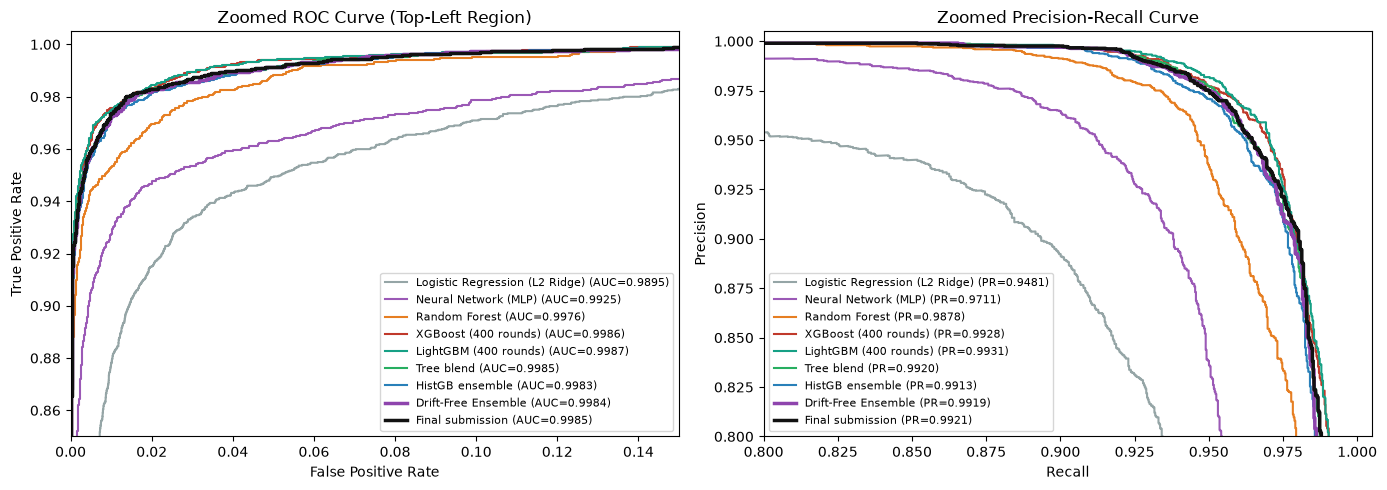

In [17]:
# Zoomed ROC and Precision-Recall curves (out-of-fold)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_models = [
    ('Logistic Regression (L2 Ridge)', '#95a5a6'), ('Neural Network (MLP)', '#9b59b6'),
    ('Random Forest', '#e67e22'), ('XGBoost (400 rounds)', '#c0392b'), ('LightGBM (400 rounds)', '#16a085'),
    ('Tree blend', '#27ae60'), ('HistGB ensemble', '#2980b9'),
    ('Drift-Free Ensemble', '#8e44ad'),
    ('Final submission', '#111111'),
]
for label, color in plot_models:
    model_p = oof[label]
    lw = 2.5 if label in ('Drift-Free Ensemble', 'Final submission') else 1.5
    fpr, tpr, _ = roc_curve(y_full, model_p)
    axes[0].plot(fpr, tpr, label=f"{label} (AUC={roc_auc_score(y_full, model_p):.4f})", color=color, lw=lw)
    prec, rec, _ = precision_recall_curve(y_full, model_p)
    axes[1].plot(rec, prec, label=f"{label} (PR={average_precision_score(y_full, model_p):.4f})", color=color, lw=lw)
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.4)
axes[0].set_xlim([0.0, 0.15]); axes[0].set_ylim([0.85, 1.005])
axes[0].set_title('Zoomed ROC Curve (Top-Left Region)')
axes[0].set_xlabel('False Positive Rate'); axes[0].set_ylabel('True Positive Rate')
axes[0].legend(loc='lower right', fontsize=8)
axes[1].set_xlim([0.80, 1.005]); axes[1].set_ylim([0.80, 1.005])
axes[1].set_title('Zoomed Precision-Recall Curve')
axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
axes[1].legend(loc='lower left', fontsize=8)
plt.tight_layout()
plt.show()

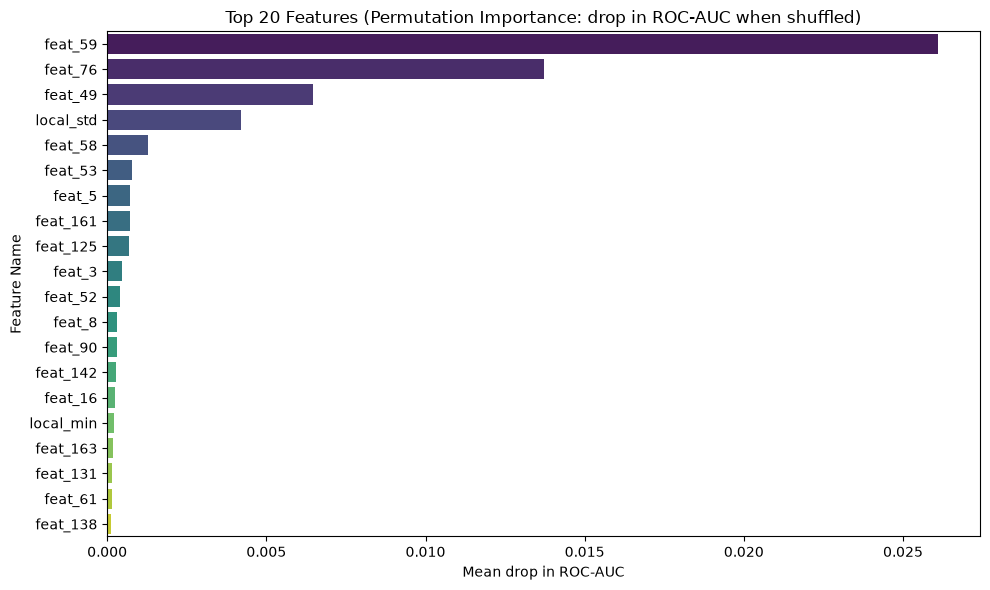

In [18]:
# Top 20 features by permutation importance (core HistGB model of the Drift-Free Ensemble, last fold, 179 features).
# Each feature is shuffled 3 times on the validation fold; a bigger drop in ROC-AUC means the model relies on it more.
perm = permutation_importance(last_fold_core_model, X_final[last_fold_val_idx], y_full[last_fold_val_idx],
                              scoring='roc_auc', n_repeats=3, random_state=RANDOM_SEED, n_jobs=1)
imp_df = pd.DataFrame({'Feature': final_cols, 'Importance': perm.importances_mean}).sort_values('Importance', ascending=False).head(20)

plt.figure(figsize=(10, 6))
sns.barplot(data=imp_df, x='Importance', y='Feature', palette='viridis')
plt.title('Top 20 Features (Permutation Importance: drop in ROC-AUC when shuffled)')
plt.xlabel('Mean drop in ROC-AUC')
plt.ylabel('Feature Name')
plt.tight_layout()
plt.show()

In [19]:
# Best F1 cutoff and prediction entropy on the out-of-fold predictions of the final submission
ths_fine = np.linspace(0.05, 0.95, 91)
f1s_fine = f1_at(oof_final, ths_fine)
best_tau = ths_fine[np.argmax(f1s_fine)]
pred_labels = (oof_final >= best_tau).astype(int)
cm = confusion_matrix(y_full, pred_labels)

p_clip = np.clip(oof_final, 1e-7, 1 - 1e-7)
entropy = -p_clip * np.log2(p_clip) - (1 - p_clip) * np.log2(1 - p_clip)
high_conf_mask = entropy < 0.20                     # H < 0.2 means p is below about 0.03 or above about 0.97

print(f"Optimal Decision Cutoff (τ*): {best_tau:.2f}")
print(f"OOF F1-Score at τ*:           {np.max(f1s_fine):.4f}")
print(f"OOF Precision at τ*:          {precision_score(y_full, pred_labels):.4f}")
print(f"OOF Recall at τ*:             {recall_score(y_full, pred_labels):.4f}")
print(f"Confusion Matrix at τ*={best_tau:.2f}:")
print(f"  True Licit (TN):   {cm[0,0]:,} | False Alarms (FP): {cm[0,1]:,}")
print(f"  Missed Fraud (FN): {cm[1,0]:,} | Caught Fraud (TP): {cm[1,1]:,}")
print(f"High-Confidence Decisions (Entropy < 0.20): {high_conf_mask.mean()*100:.1f}% of transactions (Accuracy: {(y_full[high_conf_mask] == pred_labels[high_conf_mask]).mean()*100:.2f}%)")

Optimal Decision Cutoff (τ*): 0.68
OOF F1-Score at τ*:           0.9627
OOF Precision at τ*:          0.9837
OOF Recall at τ*:             0.9426
Confusion Matrix at τ*=0.68:
  True Licit (TN):   27,534 | False Alarms (FP): 57
  Missed Fraud (FN): 209 | Caught Fraud (TP): 3,435
High-Confidence Decisions (Entropy < 0.20): 89.3% of transactions (Accuracy: 99.95%)


## 9. Final Test Predictions & File Generation
For the 15,329 test transactions, I average the Drift-Free Ensemble and the second blend 50/50 (each one averaged over its 5 fold models) and save the probabilities to `e1351028.csv`. ROC-AUC only needs the ranking, so I keep the raw probabilities instead of turning them into 0/1 labels.

In [20]:
# test_final_preds = 0.45 * test_second + 0.55 * test_drift_free
# test_final_preds = 0.4 * test_second + 0.6 * test_drift_free
test_final_preds = 0.5 * test_second + 0.5 * test_drift_free

sub_df = pd.DataFrame({'index': test_df['index'].values, 'target': test_final_preds})
sub_df.to_csv('e1351028.csv', index=False)
print("Saved predictions to e1351028.csv.")

# Sanity checks on the submission file
assert len(sub_df) == 15329, "Incorrect row count!"
assert list(sub_df.columns) == ['index', 'target'], "Incorrect column names!"
assert (sub_df['target'] >= 0.0).all() and (sub_df['target'] <= 1.0).all(), "Predictions out of bounds!"
print("All sanity checks passed!")
print(f"Total rows: {len(sub_df):,} | Mean predicted illicit probability: {sub_df['target'].mean()*100:.2f}%")

# How many transactions get a high fraud score in each test time step
step_summary = pd.DataFrame({'time_step': test_df['time_step'].values, 'p': test_final_preds}).groupby('time_step')['p'].agg(
    transactions='size', score_ge_0_5=lambda s: int((s >= 0.5).sum()), score_ge_0_2=lambda s: int((s >= 0.2).sum()))
print("\nHigh-score transactions per test time step:")
print(step_summary.T.to_string())

print("\nFirst 10 rows:")
print(sub_df.head(10).to_string(index=False))

Saved predictions to e1351028.csv.
All sanity checks passed!
Total rows: 15,329 | Mean predicted illicit probability: 7.68%

High-score transactions per test time step:
time_step       36   37   38    39    40    41    42    43    44    45   46   47   48   49
transactions  1708  498  756  1183  1211  1132  2154  1370  1591  1221  712  846  471  476
score_ge_0_5    51   29  107    82    85   119   218     7    40    16   16    5    2    6
score_ge_0_2   126   50  126   140   136   163   291    54   168    86   42   25   12   28

First 10 rows:
 index   target
     0 0.003426
     1 0.018017
     2 0.004432
     3 0.004133
     4 0.001916
     5 0.002767
     6 0.172461
     7 0.008931
     8 0.000504
     9 0.003019


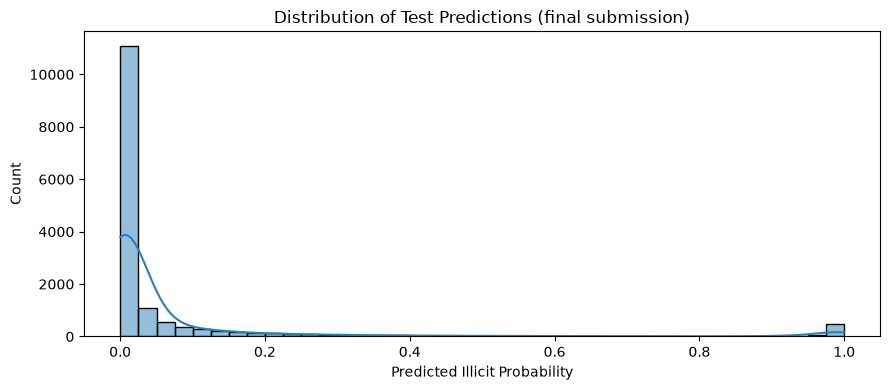

In [21]:
# Distribution of predicted test probabilities
plt.figure(figsize=(9, 4))
sns.histplot(sub_df['target'], bins=40, kde=True, color='#2980b9')
plt.title('Distribution of Test Predictions (final submission)')
plt.xlabel('Predicted Illicit Probability')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

## 10. References and Acknowledgements

### Reference Examples
* Weber, M., et al. (2019). *Anti-Money Laundering in Bitcoin: Experimenting with Graph Convolutional Networks for Financial Forensics*. KDD Workshop on Anomaly Detection in Finance [Link](https://arxiv.org/abs/1908.02591).
* Ashfaq, T., Khalid, R., et al. (2022). *A Machine Learning and Blockchain Based Efficient Fraud Detection Mechanism*. Sensors, 22(19), 7162 ([Link](https://pmc.ncbi.nlm.nih.gov/articles/PMC9572131/)).
* Jetty, N., et al. (2025). *Enhancing Bitcoin Fraud Detection with an Ensemble Model: A Deep Learning and Optimization-Based Approach*. ICoICC 2025 ([Link](https://doi.org/10.1109/ICoICC64033.2025.11052038)).
* Chawla, N. V., et al. (2002). *SMOTE: Synthetic Minority Over-sampling Technique*. Journal of Artificial Intelligence Research, 16, 321–357.
* Liu, F. T., Ting, K. M., & Zhou, Z.-H. (2008). *Isolation Forest*. IEEE International Conference on Data Mining.
* Maganti, S. (2026). *When Graph Structure Becomes a Liability: A Critical Re-Evaluation of Graph Neural Networks for Bitcoin Fraud Detection under Temporal Distribution Shift* ([Link](https://arxiv.org/abs/2604.19514)).

### Online Code Examples and Sources
* **Scikit-learn User Guide & Examples**:
  - *Histogram-based Gradient Boosting*: [Scikit-learn HistGradientBoosting](https://scikit-learn.org/stable/modules/ensemble.html#histogram-based-gradient-boosting) (number of rounds, leaf size, feature subsampling, and class weights).
  - *Permutation Importance*: [Scikit-learn Inspection](https://scikit-learn.org/stable/modules/permutation_importance.html) (feature importance measured by the drop in ROC-AUC).
  - *Robust Scaling*: [Scikit-learn Preprocessing](https://scikit-learn.org/stable/modules/preprocessing.html#scaling-data-with-outliers) (median and IQR scaling for skewed amounts).
  - *Stratified K-Fold*: [Scikit-learn Model Evaluation](https://scikit-learn.org/stable/modules/cross_validation.html#stratified-k-fold) (keeping the fraud rate equal across folds).
* **CatBoost, XGBoost & LightGBM Documentation**:
  - [CatBoost Documentation](https://catboost.ai/docs/en/concepts/python-reference_catboostclassifier), [XGBoost Documentation](https://xgboost.readthedocs.io/en/stable/python/python_api.html), [LightGBM Documentation](https://lightgbm.readthedocs.io/en/latest/pythonapi/lightgbm.LGBMClassifier.html).
* **joblib**: [Parallel and delayed](https://joblib.readthedocs.io/en/latest/parallel.html) (training independent models at the same time).
* **NetworkX Graph Algorithms**:
  - *PageRank & Connected Components*: [NetworkX Documentation](https://networkx.org/documentation/stable/reference/algorithms/index.html) (PageRank inside each time step and connected groups of transactions).

### AI Usage
* Used Antigravity (Gemini and Claude models) to help debug the code, check the implementation logic, and fix code errors.
* Used Gemini to help refine and improve the language, structure, and clarity of the notebook and final report.